**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 2**
Pandas para el análisis de datos en Python

---

*   NOMBRE: Jesús Gómez-Braña González
*   MATRÍCULA:A01841439


---

In [153]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


En esta actividad trabajarás con el archivo `cleaned_weather.csv`, un extracto del conjunto de datos meteorológicos a lo largo de todo el año 2020 en una estación del Instituto *Max Planck* (Alemania) disponible en Kaggle.

Los datos meteorológicos fueron registrados cada 10 minutos e incluyen los siguientes indicadores:

*   `timestamp`: Fecha y hora de la observación.
*   `p`: Presión atmosférica en milibares (mbar)
*   `T`: Temperatura del aire en grados Celsius (°C)
*   `Tpot`: Temperatura potencial en Kelvin (K)
*   `rh`: Humedad relativa en porcentaje (%)
*   `VPact`: Presión real de vapor en milibares (mbar)
*   `sh`: Humedad específica en gramos por kilogramo (g/kg)
*   `H2OC`: Concentración de vapor de agua en milimoles por mol (mmol/mol) de aire seco
*   `rho`: Densidad del aire en gramos por metro cúbico (g/m³)
*   `wv`: Velocidad del viento en metros por segundo (m/s)
*   `wd`: Dirección del viento en grados (°)
*   `rain`: Precipitación total en milímetros (mm)
*   `raining`: Duración de la lluvia en segundos (s)

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.


In [154]:
# Importa las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt

1.	Descarga el archivo: `cleaned_weather.csv` y guarda, en un dataframe (`weather_df`), todos sus registros.
- Determina la dimensionalidad del dataframe y obtén los identificadores de columnas.
   - La dimensionalidad del data frame es de 52696 filas con 13 columnas
- Renombra las columnas para facilitar la interpretación de los indicadores en los ejercicios siguientes:
  - `medicion, presion_atmosferica, temperatura_celsius, temperatura_kelvin, humedad_relativa, presion_vapor, humedad_especifica, concentracion_vapor, densidad_aire, velocidad_viento, direccion_viento, precipitacion_total, duracion_lluvia`
- Muestra los primeros y los últimos 5 registros.
- ¿Hay valores faltantes en el dataframe?
  - No los hay





In [155]:
weather_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Ciencia de datos/cleaned_weather.csv")
print(f"Dimensionalidad del dataframe {weather_df.shape}")
print(f"Columnas: {weather_df.columns.values}")
weather_df.columns = ["medicion", "presion_atmosferica", "temperatura_celsius", "temperatura_kelvin", "humedad_relativa", "presion_vapor", "humedad_especifica", "concentracion_vapor", "densidad_aire", "velocidad_viento", "direccion_viento", "precipitacion_total", "duracion_lluvia"]
weather_df.tail(5)

Dimensionalidad del dataframe (52696, 13)
Columnas: ['timestamp' 'p' 'T' 'Tpot' 'rh' 'VPact' 'sh' 'H2OC' 'rho' 'wv' 'wd'
 'rain' 'raining']


,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
52691,31/12/20 23:20,978.32,2.28,277.16,80.0,5.76,3.67,5.89,1234.61,0.73,180.6,0.0,0
52692,31/12/20 23:30,978.30,2.13,277.01,83.1,5.92,3.77,6.05,1235.20,0.43,174.0,0.0,0
52693,31/12/20 23:40,978.26,1.99,276.88,82.2,5.80,3.69,5.93,1235.82,0.38,248.9,0.0,0
52694,31/12/20 23:50,978.26,2.07,276.95,81.4,5.77,3.68,5.90,1235.49,0.57,196.6,0.0,0
52695,01/01/21 0:00,978.24,2.01,276.89,82.4,5.82,3.71,5.95,1235.71,0.57,221.3,0.0,0


In [156]:
print(f"Hay valores faltantes?: {sum([weather_df[column].isna().sum() for _,column in enumerate(weather_df.columns)]) > 0}")

Hay valores faltantes?: False


2. Determina el tipo de datos que tienen las columnas.
  - Los Tipos de datos son flotantes para todas las columnas a excepcion de medicion el cual es un objeto y duracoin de lluvia que es un entero
- Cambia la columna `medicion` a datetime utilizando el formato: `%d/%m/%y %H:%M`
- Obtén dos columnas adicionales separando `medicion` en `fecha` y `hora`

In [157]:
weather_df.dtypes

,0
medicion,object
presion_atmosferica,float64
temperatura_celsius,float64
temperatura_kelvin,float64
humedad_relativa,float64
presion_vapor,float64
humedad_especifica,float64
concentracion_vapor,float64
densidad_aire,float64
velocidad_viento,float64


In [158]:
weather_df.medicion = pd.to_datetime(weather_df.medicion, format="%d/%m/%y %H:%M")
weather_df["fecha"] = weather_df.medicion.dt.date
weather_df["hora"] = weather_df.medicion.dt.time
weather_df[["medicion", "fecha", "hora"]]

,medicion,fecha,hora
0,2020-01-01 00:10:00,2020-01-01,00:10:00
1,2020-01-01 00:20:00,2020-01-01,00:20:00
2,2020-01-01 00:30:00,2020-01-01,00:30:00
3,2020-01-01 00:40:00,2020-01-01,00:40:00
4,2020-01-01 00:50:00,2020-01-01,00:50:00
...,...,...,...
52691,2020-12-31 23:20:00,2020-12-31,23:20:00
52692,2020-12-31 23:30:00,2020-12-31,23:30:00
52693,2020-12-31 23:40:00,2020-12-31,23:40:00
52694,2020-12-31 23:50:00,2020-12-31,23:50:00


3. Determina la cantidad de valores únicos de cada columna.
- La columna `medicion` tiene un valor menos que el número total de filas del dataframe, lo que indica que hay una fecha duplicada. Identifica cuál es.
- Comprueba si las demás columnas también contienen los mismos valores; si es así, elimina  uno de los registros duplicados.

---
Si existia una fecha duplicada, esto se puede observar en la diferencia entre la dimensionalidad y medicion, La fecha duplicada resulto siendo el 2020-05-2020. En el duplicado todas las columnas eran iguales y por lo tanto se elimino


In [159]:
weather_df.nunique()

,0
medicion,52695
presion_atmosferica,5052
temperatura_celsius,3680
temperatura_kelvin,3836
humedad_relativa,5494
presion_vapor,2059
humedad_especifica,1337
concentracion_vapor,2087
densidad_aire,14826
velocidad_viento,977


In [160]:
print(f"Valores unicos en medicion {weather_df.medicion.nunique()}")
boolean_mask = weather_df.medicion.value_counts() >1
duplicado = weather_df.medicion.value_counts()[boolean_mask].index.values[0]
print(f"Duplicado = {duplicado}")

Valores unicos en medicion 52695
Duplicado = 2020-05-12T06:00:00.000000000


In [161]:
print("Las columnas son duplicados?")
duplicados = weather_df[weather_df.medicion == duplicado]
duplicados.iloc[0] == duplicados.iloc[1]

Las columnas son duplicados?


,0
medicion,True
presion_atmosferica,True
temperatura_celsius,True
temperatura_kelvin,True
humedad_relativa,True
presion_vapor,True
humedad_especifica,True
concentracion_vapor,True
densidad_aire,True
velocidad_viento,True


4. Imprime nuevamente las cantidad de valores únicos por columna.
- ¿Por qué son 144 horas diferentes?
  - Porque la diferencia de tiempo en cada valor de medicion es de 10 minutos, al dividir 24 horas = 1440 minutos, obtienes 144.0 distintas particiones
- La cantidad de combinaciones únicas de fecha y hora no coincide con el número total de mediciones. Aunque no haya valores NaN, esto no garantiza que no se hayan omitido registros. Identifica las fechas en las que faltan mediciones.
   - Las mediciones faltantes son el inicio de cada día. Como se comenzaba a contar dese el minuto 10 del dia, el minuto 0 fue excluido de la muestra, representando una perdida de datos de 10 minutos a lo largo de todos los dias
- Una vez concluido el análisis de mediciones faltantes, elimina todos los registros que no correspondan al año 2020 y la columna `medicion`.


In [162]:
weather_df.nunique()

,0
medicion,52695
presion_atmosferica,5052
temperatura_celsius,3680
temperatura_kelvin,3836
humedad_relativa,5494
presion_vapor,2059
humedad_especifica,1337
concentracion_vapor,2087
densidad_aire,14826
velocidad_viento,977


In [163]:
print("Por qué son 144 horas diferentes?")
print(f"Porque la diferencia de tiempo en cada valor de medicion es de 10 minutos, al dividir 24 horas = {24 * 60} minutos, obtienes {24*60/10} distintas particiones")
weather_df.medicion.diff()

Por qué son 144 horas diferentes?
Porque la diferencia de tiempo en cada valor de medicion es de 10 minutos, al dividir 24 horas = 1440 minutos, obtienes 144.0 distintas particiones


,medicion
0,NaT
1,0 days 00:10:00
2,0 days 00:10:00
3,0 days 00:10:00
4,0 days 00:10:00
...,...
52691,0 days 00:10:00
52692,0 days 00:10:00
52693,0 days 00:10:00
52694,0 days 00:10:00


In [164]:
interval = pd.date_range(weather_df.medicion.min(), weather_df.medicion.max())
print(f"Cantidad de fechas y horas no consideradas {len([date if date not in weather_df.medicion else None for date in interval])}")
print(f"Cantidad de fechas no consideradas {len([date.date() for date in interval if date.date() not in weather_df.fecha.values])}")

Cantidad de fechas y horas no consideradas 366
Cantidad de fechas no consideradas 0


In [165]:
print("Fechas no consideradas")
print([date if date not in weather_df.medicion else None for date in interval])

Fechas no consideradas
[Timestamp('2020-01-01 00:10:00'), Timestamp('2020-01-02 00:10:00'), Timestamp('2020-01-03 00:10:00'), Timestamp('2020-01-04 00:10:00'), Timestamp('2020-01-05 00:10:00'), Timestamp('2020-01-06 00:10:00'), Timestamp('2020-01-07 00:10:00'), Timestamp('2020-01-08 00:10:00'), Timestamp('2020-01-09 00:10:00'), Timestamp('2020-01-10 00:10:00'), Timestamp('2020-01-11 00:10:00'), Timestamp('2020-01-12 00:10:00'), Timestamp('2020-01-13 00:10:00'), Timestamp('2020-01-14 00:10:00'), Timestamp('2020-01-15 00:10:00'), Timestamp('2020-01-16 00:10:00'), Timestamp('2020-01-17 00:10:00'), Timestamp('2020-01-18 00:10:00'), Timestamp('2020-01-19 00:10:00'), Timestamp('2020-01-20 00:10:00'), Timestamp('2020-01-21 00:10:00'), Timestamp('2020-01-22 00:10:00'), Timestamp('2020-01-23 00:10:00'), Timestamp('2020-01-24 00:10:00'), Timestamp('2020-01-25 00:10:00'), Timestamp('2020-01-26 00:10:00'), Timestamp('2020-01-27 00:10:00'), Timestamp('2020-01-28 00:10:00'), Timestamp('2020-01-29 00

In [166]:
weather_df = weather_df[weather_df.medicion.dt.year == 2020]
weather_df.drop(columns="medicion", inplace=True)
weather_df

,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia,fecha,hora
0,1008.89,0.71,273.18,86.10,5.54,3.42,5.49,1280.62,1.02,224.3,0.0,0,2020-01-01,00:10:00
1,1008.76,0.75,273.22,85.20,5.49,3.39,5.45,1280.33,0.43,206.8,0.0,0,2020-01-01,00:20:00
2,1008.66,0.73,273.21,85.10,5.48,3.39,5.43,1280.29,0.61,197.1,0.0,0,2020-01-01,00:30:00
3,1008.64,0.37,272.86,86.30,5.41,3.35,5.37,1281.97,1.11,206.4,0.0,0,2020-01-01,00:40:00
4,1008.61,0.33,272.82,87.40,5.47,3.38,5.42,1282.08,0.49,209.6,0.0,0,2020-01-01,00:50:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52690,978.36,2.27,277.15,79.04,5.69,3.63,5.82,1234.73,1.08,200.1,0.0,0,2020-12-31,23:10:00
52691,978.32,2.28,277.16,80.00,5.76,3.67,5.89,1234.61,0.73,180.6,0.0,0,2020-12-31,23:20:00
52692,978.30,2.13,277.01,83.10,5.92,3.77,6.05,1235.20,0.43,174.0,0.0,0,2020-12-31,23:30:00
52693,978.26,1.99,276.88,82.20,5.80,3.69,5.93,1235.82,0.38,248.9,0.0,0,2020-12-31,23:40:00


5. Obtén un dataframe `indicadores_diarios` que sólo almacene el mayor valor de las mediciones por fecha para responder:
- ¿Cuál fue la máxima precipitación y a qué fecha pertenece?
  - Fecha: 2020-06-16, precipitacion: 11.2
- ¿Cuáles fueron los tres días con las velocidades de viento más altas registradas?
  - 2020-02-10, 2020-02-16, 2020-02-09
- ¿Cuántos días rebasaron el 90% de humedad relativa y los 30° celsius?
  - 5 días

In [167]:
indicadores_diarios = weather_df.groupby("fecha").max()
print(f"¿Cuál fue la máxima precipitación y a qué fecha pertenece? Fecha: {indicadores_diarios[indicadores_diarios.precipitacion_total == indicadores_diarios.precipitacion_total.max()].index.values[0]}, precipitacion: {indicadores_diarios.precipitacion_total.max()}")
print(f"¿Cuáles fueron los tres días con las velocidades de viento más altas registradas? {indicadores_diarios.velocidad_viento.sort_values(ascending=False).head(3)}")
print(f"¿Cuántos días rebasaron el 90% de humedad relativa y los 30 celsius? {indicadores_diarios[(indicadores_diarios.humedad_relativa > 90) & (indicadores_diarios.temperatura_celsius > 30)].shape[0]} días")

¿Cuál fue la máxima precipitación y a qué fecha pertenece? Fecha: 2020-06-16, precipitacion: 11.2
¿Cuáles fueron los tres días con las velocidades de viento más altas registradas? fecha
2020-02-10    13.77
2020-02-16    13.00
2020-02-09    12.52
Name: velocidad_viento, dtype: float64
¿Cuántos días rebasaron el 90% de humedad relativa y los 30 celsius? 5 días


6. La función `describe()` resume múltiples estadísticas descriptivas. Utiliza esta función para explorar y responder las preguntas sobre las variables en el dataframe de `indicadores_diarios `:
- ¿Cuál es la desviación estándar de la concentración de vapor y qué indica?
  - 4.5, lo que significa que en promedio la concentración de vapor en un dia normalmente se encuentra 4.57 H2OCs de distancia de la media
- ¿Cuál es la mediana de la presión atmosférica y qué significa?
  - 993.3, lo cual significa que la presion atmosferica en el dia en la mitad de toda la muestra es de 993.3
- ¿Cuál es el tercer cuartil de la duración de la lluvia y cómo se interpreta?
  - El tercer cuartil de la duracion de la lluvia es 600.0 lo que significa que el 75% de los dias tienen una duracion menor que 600.0

In [168]:
metricos = indicadores_diarios.describe()
metricos

,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,992.977842,15.343770,289.431667,90.886530,11.409454,7.214016,11.539180,1232.622814,5.245164,317.673689,0.314208,240.382514
std,8.543447,7.850339,7.942175,9.201588,4.507555,2.872647,4.573267,32.702446,2.097012,50.611324,0.979721,273.840002
min,959.900000,-0.120000,273.460000,55.440000,3.320000,2.050000,3.290000,1167.050000,1.570000,69.570000,0.000000,0.000000
25%,988.015000,8.840000,282.732500,85.400000,7.647500,4.832500,7.742500,1207.590000,3.662500,279.075000,0.000000,0.000000
50%,993.300000,15.060000,289.160000,93.250000,10.715000,6.705000,10.735000,1231.455000,4.880000,346.650000,0.000000,0.000000
75%,998.432500,21.695000,295.957500,99.900000,14.462500,9.180000,14.685000,1256.057500,6.495000,357.300000,0.200000,600.000000
max,1020.070000,34.800000,309.130000,100.000000,24.160000,15.400000,24.530000,1318.520000,13.770000,360.000000,11.200000,600.000000


In [169]:

print(f"La desviacion estandar de la concentracion de vapor es {round(metricos.concentracion_vapor['std'],2)}")
print(f"lo que significa que en promedio la concentración de vapor en un dia normalmente se encuentra {round(metricos.concentracion_vapor['std'],2)} H2OCs de distancia de la media")
print(f"La mediana de la presion atmosferica es {metricos.presion_atmosferica['50%']}")
print(f"Lo cual significa que la presion atmosferica en el dia en la mitad de toda la muestra es de {metricos.presion_atmosferica['50%']}")
print(f"El tercer cuartil de la duracion de la lluvia es {metricos.duracion_lluvia['75%']} lo que significa que el 75% de los dias tienen una duracion menor que {metricos.duracion_lluvia['75%']}")

La desviacion estandar de la concentracion de vapor es 4.57
lo que significa que en promedio la concentración de vapor en un dia normalmente se encuentra 4.57 H2OCs de distancia de la media
La mediana de la presion atmosferica es 993.3
Lo cual significa que la presion atmosferica en el dia en la mitad de toda la muestra es de 993.3
El tercer cuartil de la duracion de la lluvia es 600.0 lo que significa que el 75% de los dias tienen una duracion menor que 600.0


7.	Dibuja un histograma para cada una de las columnas de `indicadores_diarios`.

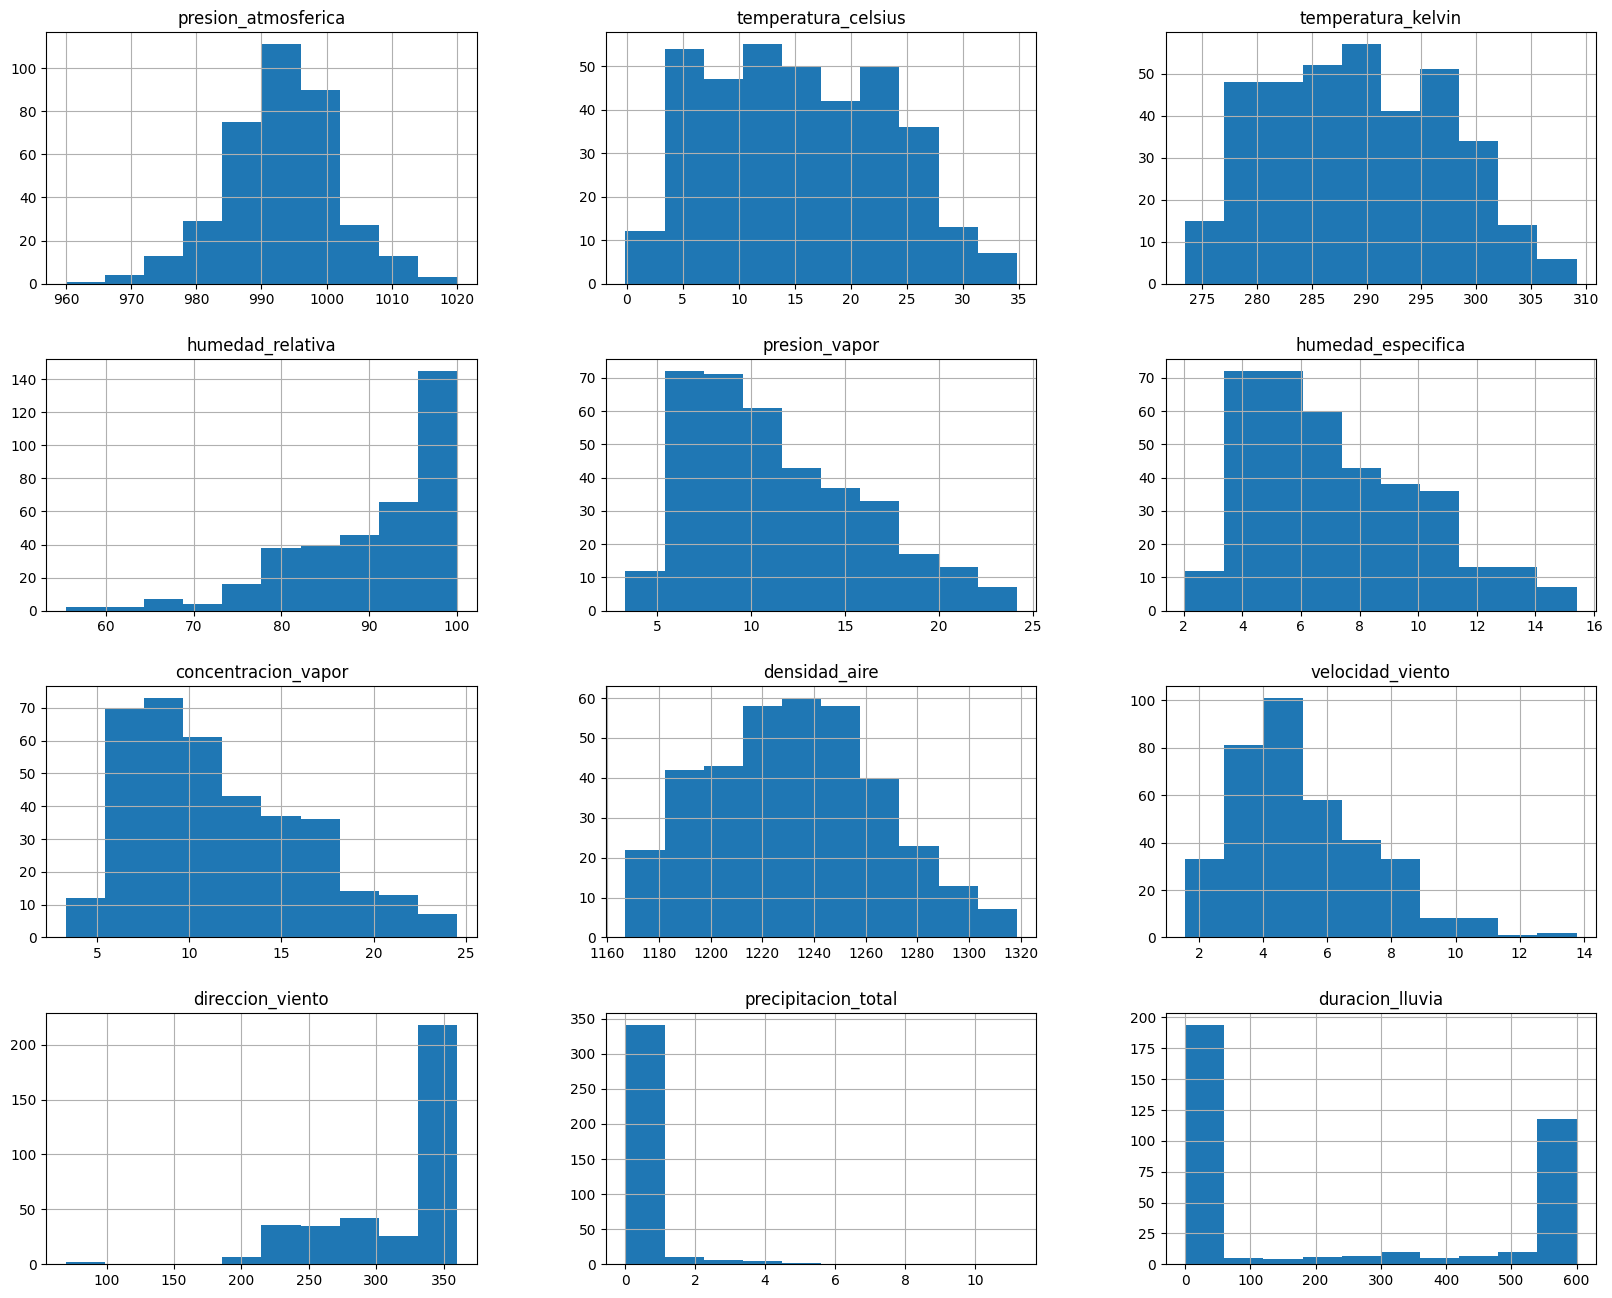

In [170]:
indicadores_diarios.hist(figsize=(20,16));

8. Utiliza el dataframe de indicadores diarios para crear un nuevo dataframe `indicadores_mensuales`. Para ello:
- Crea una nueva columna `mes` a partir de la fecha que se encuentra en el índice.
- Haciendo uso de `groupby()`, calcula los promedios mensuales y conserva únicamente las columnas `humedad_relativa`, `temperatura_celsius` y `velocidad_viento` en el nuevo dataframe.

In [171]:
indicadores_diarios["mes"] = pd.to_datetime(indicadores_diarios.index).month
indicadores_mensuales = indicadores_diarios.groupby("mes")[["humedad_relativa", "temperatura_celsius", "velocidad_viento"]].mean()
indicadores_mensuales

,humedad_relativa,temperatura_celsius,velocidad_viento
mes,,,
1,89.776129,6.821290,5.031935
2,85.719655,8.962414,7.489655
3,85.372903,9.683871,6.421290
4,80.938667,16.879667,4.997000
5,87.464839,17.135484,4.865806
6,94.256000,22.212000,5.296667
7,85.959355,24.336129,4.830323
8,92.002581,26.097742,5.040323
9,97.570000,21.571667,4.153333


9. Construye el mismo dataframe mensual, pero esta vez utilizando la función `pivot_table()`.
- Añade la columna `indice_calor` usando la fórmula de Thom (*Temperature - Humidity Index*, TDI):
> `temperatura_celsius + 0.33 x humedad_relativa - 0.7 x velocidad_viento - 4`

In [172]:
pivot = indicadores_diarios.pivot_table(index="mes", values=["humedad_relativa", "temperatura_celsius", "velocidad_viento"], aggfunc="mean")
pivot

,humedad_relativa,temperatura_celsius,velocidad_viento
mes,,,
1,89.776129,6.821290,5.031935
2,85.719655,8.962414,7.489655
3,85.372903,9.683871,6.421290
4,80.938667,16.879667,4.997000
5,87.464839,17.135484,4.865806
6,94.256000,22.212000,5.296667
7,85.959355,24.336129,4.830323
8,92.002581,26.097742,5.040323
9,97.570000,21.571667,4.153333


In [173]:
pivot["indice_calor"] = pivot.temperatura_celsius + 0.33 * pivot.humedad_relativa - 0.7 * pivot.velocidad_viento - 4
pivot

,humedad_relativa,temperatura_celsius,velocidad_viento,indice_calor
mes,,,,
1,89.776129,6.821290,5.031935,28.925058
2,85.719655,8.962414,7.489655,28.007141
3,85.372903,9.683871,6.421290,29.362026
4,80.938667,16.879667,4.997000,36.091527
5,87.464839,17.135484,4.865806,38.592816
6,94.256000,22.212000,5.296667,45.608813
7,85.959355,24.336129,4.830323,45.321490
8,92.002581,26.097742,5.040323,48.930368
9,97.570000,21.571667,4.153333,46.862433


10. Recuerda que de las cuatro funciones estudiadas para manipular la estructura del dataframe:
- `melt/pivot` hacen las transformaciones de manera controlada, es decir puedes
definir por medio de sus parámetros qué variables quedarán como índices, columnas y valores.
- `stack/unstack` la conversión se aplica siempre sobre los niveles inferiores de index/columns.
- Convierte el dataframe del ejercicio anterior a formato largo usando: `melt()` y `stack()` y comenta las diferencias.

---
### Diferencias
Ambos metodos conviertieron las columnas en filas, pero melt creo un nuevo indice, lo cual ya no permite observar de que mes es cual dato. Mientras que stack mantuvo la agrupacion, mostrando de que mes pertenece cada valor.

In [174]:
pivot.melt()

,variable,value
0,humedad_relativa,89.776129
1,humedad_relativa,85.719655
2,humedad_relativa,85.372903
3,humedad_relativa,80.938667
4,humedad_relativa,87.464839
5,humedad_relativa,94.256000
6,humedad_relativa,85.959355
7,humedad_relativa,92.002581
8,humedad_relativa,97.570000
9,humedad_relativa,96.950645


In [175]:
pivot.stack()

mes                     
1    humedad_relativa       89.776129
     temperatura_celsius     6.821290
     velocidad_viento        5.031935
     indice_calor           28.925058
2    humedad_relativa       85.719655
     temperatura_celsius     8.962414
     velocidad_viento        7.489655
     indice_calor           28.007141
3    humedad_relativa       85.372903
     temperatura_celsius     9.683871
     velocidad_viento        6.421290
     indice_calor           29.362026
4    humedad_relativa       80.938667
     temperatura_celsius    16.879667
     velocidad_viento        4.997000
     indice_calor           36.091527
5    humedad_relativa       87.464839
     temperatura_celsius    17.135484
     velocidad_viento        4.865806
     indice_calor           38.592816
6    humedad_relativa       94.256000
     temperatura_celsius    22.212000
     velocidad_viento        5.296667
     indice_calor           45.608813
7    humedad_relativa       85.959355
     temperatura_celsius    24.336129
     velocidad_viento        4.830323
     indice_calor           45.321490
8    humedad_relativa       92.002581
     temperatura_celsius    26.097742
     velocidad_viento        5.040323
     indice_calor           48.930368
9    humedad_relativa       97.570000
     temperatura_celsius    21.571667
     velocidad_viento        4.153333
     indice_calor           46.862433
10   humedad_relativa       96.950645
     temperatura_celsius    14.089355
     velocidad_viento        5.675484
     indice_calor           38.110229
11   humedad_relativa       96.983333
     temperatura_celsius    10.561667
     velocidad_viento        4.399000
     indice_calor           35.486867
12   humedad_relativa       97.510968
     temperatura_celsius     5.680000
     velocidad_viento        4.817097
     indice_calor           30.486652
dtype: float64

---

**Declaración de uso de IA**

Google. (2026). Gemini (basado en 2.5 Flash) [Modelo de lenguaje grande], utilizado para depuración

---

Referencias:

https://pandas.pydata.org/docs/user_guide/timeseries.html

https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.diff.html

https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.period_range.html